# Building an AI-powered multimodal RAG system with Docling and Granite

*Using IBM Granite vision, text-based embeddings and generative AI models*

## Multimodal retrieval-augmented generation

[Retrieval-augmented generation (RAG)](https://www.ibm.com/think/topics/retrieval-augmented-generation) is a technique used with large language models (LLMs) to connect the model with a knowledge base of information outside the data the LLM has been trained on without having to perform [fine-tuning](https://www.ibm.com/think/topics/rag-vs-fine-tuning). Traditional RAG is limited to text-based use cases such as text summarization and chatbots.

Multimodal RAG can use [multimodal](https://www.ibm.com/think/topics/multimodal-ai) LLMs (MLLM) to process information from multiple types of data to be included as part of the external knowledge base used in RAG. Multimodal data can include text, images, audio, video or other forms. Popular multimodal LLMs include Google’s Gemini, Meta’s Llama 4 and OpenAI’s GPT-5.4. 


For this recipe, you will use an IBM Granite model capable of processing different modalities. You will create an AI system to answer real-time user queries from unstructured data in a PDF.

## Recipe overview

Welcome to this Granite recipe. In this recipe, you'll learn how to harness the power of advanced tools to build an AI-powered multimodal RAG pipeline. This tutorial will guide you through the following processes:

- **Document preprocessing:** Learn how to handle documents from various sources, parse and transform them into usable formats and store them in vector databases by using Docling. You will use a Granite MLLM to generate image descriptions of images in the documents.
- **RAG:** Understand how to connect LLMs such as Granite with external knowledge bases to enhance query responses and generate valuable insights.
- **LangChain for workflow integration:** Discover how to use LangChain to streamline and orchestrate document processing and retrieval workflows, enabling seamless interaction between different components of the system.

This recipe uses three cutting-edge technologies:

1. **[Docling](https://docling-project.github.io/docling/):** An open-source toolkit used to parse and convert documents.
2. **[Granite](https://www.ibm.com/granite/docs/models/granite/):** A state-of-the-art LLM that provides robust natural language capabilities and a vision language model that provides image to text generation.
3. **[LangChain](https://github.com/langchain-ai/langchain):** A powerful framework used to build applications powered by language models, designed to simplify complex workflows and integrate external tools seamlessly.

By the end of this recipe, you will accomplish the following:
- Gain proficiency in document preprocessing, chunking and image understanding.
- Integrate vector databases to enhance retrieval capabilities.
- Use RAG to perform efficient and accurate data retrieval for real-world applications.

This recipe is designed for AI developers, researchers and enthusiasts looking to enhance their knowledge of document management and advanced natural language processing (NLP) techniques.


## Prerequisites

- Familiarity with Python programming.
- Basic understanding of LLMs, NLP concepts and computer vision.

## Step 1: Setting up the environment

Install dependencies.

In [ ]:
! echo "::group::Install Dependencies"
%pip install uv
! uv pip install "git+https://github.com/ibm-granite-community/utils.git" \
    transformers \
    pillow \
    langchain_classic \
    langchain_core \
    langchain_huggingface sentence_transformers \
    langchain_chroma chromadb pysqlite3 \
    docling \
    langchain-huggingface\
    opencv-python \
    "langchain_replicate @ git+https://github.com/ibm-granite-community/langchain-replicate.git"
! echo "::endgroup::"

::group::Install Dependencies
/Users/gary/Documents/Demos/IFSA-students/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.
Using Python 3.12.11 environment at: /Users/gary/Documents/Demos/IFSA-students/.venv
Resolved 157 packages in 1.32s                                       
Audited 157 packages in 0.38ms
::endgroup::


## Step 2: Selecting the AI models

### Logging

To see some logging information, we can configure INFO log level.

NOTE: It is okay to skip running this cell.

In [2]:
import logging

logging.basicConfig(level=logging.INFO)

### Load the Granite models

Specify the embeddings model to use for generating text embedding vectors. Here we will use one of the [Granite Embeddings models](https://huggingface.co/collections/ibm-granite/granite-embedding-models-6750b30c802c1926a35550bb)

To use a different embeddings model, replace this code cell with one from [this Embeddings Model recipe](https://github.com/ibm-granite-community/granite-kitchen/blob/main/recipes/Components/Langchain_Embeddings_Models.ipynb).

In [3]:
from langchain_huggingface import HuggingFaceEmbeddings
from transformers import AutoTokenizer

embeddings_model_path = "ibm-granite/granite-embedding-30m-english"
embeddings_model = HuggingFaceEmbeddings(
    model_name=embeddings_model_path,
)
embeddings_tokenizer = AutoTokenizer.from_pretrained(embeddings_model_path)

/Users/gary/Documents/Demos/IFSA-students/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO:sentence_transformers.base.model:No device provided, using mps
INFO:httpx:HTTP Request: HEAD https://huggingface.co/ibm-granite/granite-embedding-30m-english/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ibm-granite/granite-embedding-30m-english/9b5b096411652ec1189c68fcfb90d0a82c5b45af/modules.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/ibm-granite/granite-embedding-30m-english/resolve/main/config_sentence_transformers.json "HTTP/1.1 404 Not Found"
INFO:sentence_transformers.base.model:Loading SentenceTransformer model from ibm-granite/granite-embedding-30m-english.
INFO:httpx:HTTP 

Specify the MLLM to use for image understanding. We will use the Granite vision model.

In [4]:
from ibm_granite_community.notebook_utils import get_env_var
from langchain_replicate import Replicate
from transformers import AutoProcessor

vision_model_path = "ibm-granite/granite-vision-3.3-2b"
vision_model = Replicate(
    model=vision_model_path,
    replicate_api_token=get_env_var("REPLICATE_API_TOKEN"),
    model_kwargs={
        "max_tokens": embeddings_tokenizer.max_len_single_sentence, # Set the maximum number of tokens to generate as output.
        "min_tokens": 100, # Set the minimum number of tokens to generate as output.
    },
)
vision_processor = AutoProcessor.from_pretrained(vision_model_path)

INFO:httpx:HTTP Request: HEAD https://huggingface.co/ibm-granite/granite-vision-3.3-2b/resolve/main/processor_config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ibm-granite/granite-vision-3.3-2b/bf66a8244401a8e26d2ff429aa82df8550a289e5/processor_config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/ibm-granite/granite-vision-3.3-2b/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/ibm-granite/granite-vision-3.3-2b/resolve/main/processor_config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ibm-granite/granite-vision-3.3-2b/bf66a8244401a8e26d2ff429aa82df8550a289e5/processor_config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/ibm-granite/granite-vision-3.3-2b/resolve/main/chat_template.j

Specify the language model to use for the RAG generation operation. Here we use the Replicate LangChain client to connect to a Granite model from the [`ibm-granite`](https://replicate.com/ibm-granite) org on Replicate.

To get set up with Replicate, see [Getting Started with Replicate](https://github.com/ibm-granite-community/granite-kitchen/blob/main/recipes/Getting_Started/Getting_Started_with_Replicate.ipynb).

To connect to a model on a provider other than Replicate, substitute this code cell with one from the [LLM component recipe](https://github.com/ibm-granite-community/granite-kitchen/blob/main/recipes/Components/Langchain_LLMs.ipynb).

In [5]:
from langchain_replicate import ChatReplicate

model_path = "ibm-granite/granite-4.0-h-small"
model = ChatReplicate(
    model=model_path,
    replicate_api_token=get_env_var("REPLICATE_API_TOKEN"),
    model_kwargs={
        "max_tokens": 1000, # Set the maximum number of tokens to generate as output.
        "min_tokens": 100, # Set the minimum number of tokens to generate as output.
    },
)

## Step 3: Preparing the documents for the vector database

In this example, from a set of source documents, we use [Docling](https://docling-project.github.io/docling/) to convert the documents into text and images. The text is then split into chunks. The images are processed by the MLLM to generate image summaries.

### Use Docling to download the documents and convert to text and images

Docling will download the PDF documents and process them so we can obtain the text and images the documents contain. In the PDF, there are various data types, including text, tables, graphs and images.

In [ ]:
import subprocess
subprocess.run(
    ["pip", "install", "opencv-python-headless", "--upgrade"],
    check=True
)

In [ ]:
from docling.document_converter import DocumentConverter, PdfFormatOption
from docling.datamodel.base_models import InputFormat
from docling.datamodel.pipeline_options import PdfPipelineOptions
from urllib.parse import urlparse

pdf_pipeline_options = PdfPipelineOptions(
    do_ocr=False,
    generate_picture_images=True,
)
format_options = {
    InputFormat.PDF: PdfFormatOption(pipeline_options=pdf_pipeline_options),
}
converter = DocumentConverter(format_options=format_options)

sources = [
    "https://arxiv.org/pdf/1706.03762.pdf", # EXAMPLE 1 - Attention is all you need paper
    # "https://web.archive.org/web/20230523232035if_/https://www.midwestfoodbank.org/images/AR_2020_WEB2.pdf",  # EXAMPLE 2 - Midwest Food Bank 2020 Annual Report
]
conversions = { urlparse(source).path.rstrip("/").split("/")[-1]: converter.convert(source=source).document for source in sources }

INFO:docling.datamodel.document:detected formats: [<InputFormat.PDF: 'pdf'>]
INFO:docling.document_converter:Going to convert document batch...
INFO:docling.document_converter:Initializing pipeline for StandardPdfPipeline with options hash a322942a78df07fb56176b7be9796481
INFO:docling.models.factories.base_factory:Loading plugin 'docling_defaults'
INFO:docling.models.factories:Registered picture descriptions: ['picture_description_vlm_engine', 'vlm', 'api']
INFO:docling.models.factories.base_factory:Loading plugin 'docling_defaults'
INFO:docling.models.factories:Registered ocr engines: ['auto', 'easyocr', 'kserve_v2_ocr', 'ocrmac', 'rapidocr', 'tesserocr', 'tesseract']
INFO:docling.models.factories.base_factory:Loading plugin 'docling_defaults'
INFO:docling.models.factories:Registered layout engines: ['layout_object_detection', 'docling_layout_default', 'docling_experimental_table_crops_layout']
INFO:docling.utils.accelerator_utils:Accelerator device: 'mps'
INFO:httpx:HTTP Request: GET

With the documents processed, we then further process the text elements in the documents. We chunk them into appropriate sizes for the embeddings model we are using. A list of LangChain documents are created from the text chunks.

In [7]:
from docling_core.transforms.chunker.hybrid_chunker import HybridChunker
from docling_core.types.doc.document import TableItem
from langchain_core.documents import Document

doc_id = 0
texts: list[Document] = []
for source, docling_document in conversions.items():
    for chunk in HybridChunker(tokenizer=embeddings_tokenizer).chunk(docling_document):
        items = chunk.meta.doc_items
        if len(items) == 1 and isinstance(items[0], TableItem):
            continue # we will process tables later
        refs = " ".join(map(lambda item: item.get_ref().cref, items))
        print(refs)
        text = chunk.text
        document = Document(
            page_content=text,
            metadata={
                "doc_id": (doc_id:=doc_id+1),
                "source": source,
                "ref": refs,
            },
        )
        texts.append(document)

print(f"{len(texts)} text document chunks created")

INFO:httpx:HTTP Request: HEAD https://huggingface.co/ibm-granite/granite-embedding-30m-english/resolve/main/sentence_bert_config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/ibm-granite/granite-embedding-30m-english/9b5b096411652ec1189c68fcfb90d0a82c5b45af/sentence_bert_config.json "HTTP/1.1 200 OK"
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (922 > 512). Running this sequence through the model will result in indexing errors


#/texts/1
#/texts/3 #/texts/4 #/texts/5 #/texts/6 #/texts/7
#/texts/9 #/texts/10 #/texts/11 #/texts/12
#/texts/15 #/texts/16 #/texts/17 #/texts/18
#/texts/20 #/texts/21 #/texts/22 #/texts/23
#/texts/25 #/texts/27 #/texts/28
#/texts/30 #/texts/31
#/texts/33
#/texts/36 #/texts/38
#/texts/40 #/texts/41 #/texts/42 #/texts/43 #/texts/44
#/texts/46 #/texts/47 #/texts/49 #/texts/50 #/texts/51 #/texts/52
#/texts/54 #/texts/55 #/texts/56 #/texts/57
#/texts/59 #/texts/60 #/texts/61
#/texts/63 #/texts/65 #/tables/0
#/texts/67 #/texts/68 #/texts/69 #/texts/70 #/texts/71
#/texts/73 #/texts/74 #/texts/75 #/texts/76
#/texts/78 #/texts/79
#/texts/81
#/texts/83
#/texts/85
#/texts/87 #/texts/88 #/texts/89
#/texts/91 #/texts/93
#/tables/1 #/texts/94
#/texts/95
#/texts/98 #/texts/99 #/texts/100 #/texts/101
#/texts/103 #/texts/104 #/texts/106
#/tables/2 #/texts/107 #/texts/108
#/texts/110 #/texts/111 #/texts/112
#/texts/114 #/tables/3
#/texts/115 #/texts/116
#/texts/118 #/texts/119 #/texts/120 #/texts/121 

Next we process any tables in the documents. We convert the table data to markdown format for passing into the language model. A list of LangChain documents are created from the table's markdown renderings.

In [8]:
from docling_core.types.doc.labels import DocItemLabel

doc_id = len(texts)
tables: list[Document] = []
for source, docling_document in conversions.items():
    for table in docling_document.tables:
        if table.label in [DocItemLabel.TABLE]:
            ref = table.get_ref().cref
            print(ref)
            text = table.export_to_markdown(docling_document)
            document = Document(
                page_content=text,
                metadata={
                    "doc_id": (doc_id:=doc_id+1),
                    "source": source,
                    "ref": ref
                },
            )
            tables.append(document)


print(f"{len(tables)} table documents created")

#/tables/0
#/tables/1
#/tables/2
#/tables/3
4 table documents created


Finally we process any images in the documents. Here we use the vision language model to understand the content of an image. In this example, we are interested in any textual information in the image. You might want to experiment with different prompt text to see how it might improve the results.

NOTE: Processing the images can take a very long time depending upon the number of images and the service running the vision language model.

In [9]:
import base64
import io
import PIL.Image
import PIL.ImageOps
from ibm_granite_community.langchain.prompts import TokenizerChatPromptTemplate
from langchain_core.messages import HumanMessage

def encode_image(image: PIL.Image.Image, format: str = "png") -> str:
    image = PIL.ImageOps.exif_transpose(image) or image
    image = image.convert("RGB")

    buffer = io.BytesIO()
    image.save(buffer, format)
    encoding = base64.b64encode(buffer.getvalue()).decode("utf-8")
    uri = f"data:image/{format};base64,{encoding}"
    return uri

# Feel free to experiment with this prompt
image_prompt = "If the image contains text, explain the text in the image."
vision_prompt_template = TokenizerChatPromptTemplate.from_messages(
    messages=[
        HumanMessage(content=[
            {"type": "image"},
            {"type": "text", "text": image_prompt},
        ]),
    ],
    tokenizer=vision_processor)
vision_prompt = vision_prompt_template.format_prompt()

pictures: list[Document] = []
doc_id = len(texts) + len(tables)
for source, docling_document in conversions.items():
    for picture in docling_document.pictures:
        ref = picture.get_ref().cref
        print(ref)
        image = picture.get_image(docling_document)
        if image:
            text = vision_model.invoke(vision_prompt, images=[encode_image(image)])
            document = Document(
                page_content=text,
                metadata={
                    "doc_id": (doc_id:=doc_id+1),
                    "source": source,
                    "ref": ref,
                },
            )
            pictures.append(document)

print(f"{len(pictures)} image descriptions created")

#/pictures/0


INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/models/ibm-granite/granite-vision-3.3-2b "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST https://api.replicate.com/v1/models/ibm-granite/granite-vision-3.3-2b/predictions "HTTP/1.1 201 Created"
INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/g7py128pdxrmt0cxssb8b03z4c "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/g7py128pdxrmt0cxssb8b03z4c "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/g7py128pdxrmt0cxssb8b03z4c "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/g7py128pdxrmt0cxssb8b03z4c "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/g7py128pdxrmt0cxssb8b03z4c "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST https://api.replicate.com/v1/models/ibm-granite/granite-vision-3.3-2b/predictions "HTTP/1.1 201 Created"


#/pictures/1


INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/tjmd28h3mdrmt0cxssbakt2cbg "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/tjmd28h3mdrmt0cxssbakt2cbg "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/tjmd28h3mdrmt0cxssbakt2cbg "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/tjmd28h3mdrmt0cxssbakt2cbg "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST https://api.replicate.com/v1/models/ibm-granite/granite-vision-3.3-2b/predictions "HTTP/1.1 201 Created"


#/pictures/2


INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/y7hpc01f6drmt0cxssbashx9qm "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/y7hpc01f6drmt0cxssbashx9qm "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/y7hpc01f6drmt0cxssbashx9qm "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST https://api.replicate.com/v1/models/ibm-granite/granite-vision-3.3-2b/predictions "HTTP/1.1 201 Created"


... (3 outputs left out)

INFO:httpx:HTTP Request: POST https://api.replicate.com/v1/models/ibm-granite/granite-vision-3.3-2b/predictions "HTTP/1.1 201 Created"
INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/n321j920z5rmr0cxssbb7g62zr "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/n321j920z5rmr0cxssbb7g62zr "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/n321j920z5rmr0cxssbb7g62zr "HTTP/1.1 200 OK"


#/pictures/5


INFO:httpx:HTTP Request: POST https://api.replicate.com/v1/models/ibm-granite/granite-vision-3.3-2b/predictions "HTTP/1.1 201 Created"
INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/r79y9et9s5rmw0cxssb9sjkjpw "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/r79y9et9s5rmw0cxssb9sjkjpw "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/r79y9et9s5rmw0cxssb9sjkjpw "HTTP/1.1 200 OK"


6 image descriptions created


We can then display the LangChain documents created from the input documents.

Document ID: 1
Source: 1706.03762.pdf
Content:
Provided proper attribution is provided, Google hereby grants permission to reproduce the tables and figures in this paper solely for use in journalistic or scholarly works.
Document ID: 2
Source: 1706.03762.pdf
Content:
Ashish Vaswani ∗ Google Brain avaswani@google.com Noam Shazeer ∗ Google Brain noam@google.com
Llion Jones ∗ Google Research llion@google.com Niki Parmar ∗ Google Research nikip@google.com Aidan N. Gomez ∗ † University of Toronto aidan@cs.toronto.edu Jakob Uszkoreit ∗ Google Research usz@google.com Łukasz Kaiser ∗ Google Brain lukaszkaiser@google.com
∗ ‡
Illia Polosukhin
illia.polosukhin@gmail.com
Document ID: 3
Source: 1706.03762.pdf
Content:
The dominant sequence transduction models are based on complex recurrent or convolutional neural networks that include an encoder and a decoder. The best performing models also connect the encoder and decoder through an attention mechanism. We propose a new simple network architecture

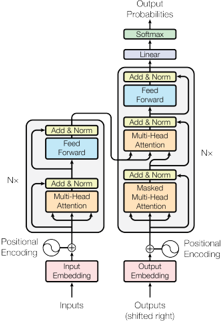

Document ID: 44
Source: 1706.03762.pdf
Content:
The text in the image is a flowchart that outlines a process. It starts with "MatMul," which is likely an acronym for matrix multiplication, a common operation in linear algebra. This is followed by "SoftMax," a function that is used in machine learning to normalize a vector of real numbers. The "Mask (opt.)" suggests an optional masking process, which is a technique used in neural networks to control the flow of data. The "Scale" step indicates that a scaling factor is applied to the data. Finally, "MatMul" is repeated, which could mean that the process is being applied twice. The flowchart is structured in a way that suggests it might be used in a computational or machine learning context, possibly for image processing or neural network training.
Image:


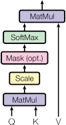

Document ID: 45
Source: 1706.03762.pdf
Content:
The text in the image is not fully legible due to the resolution of the image. However, the visible text includes "Multi-Head Attention" at the top, which is a term commonly used in machine learning and neural networks. It refers to a method used in attention mechanisms that allows the model to attend to different positions in the input data, which can be particularly useful in tasks involving sequence data like natural language processing. The specific details of the text, such as the exact implementation or the context in which it is used, cannot be accurately determined from the image provided.
Image:


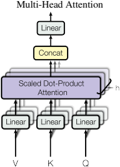

Document ID: 46
Source: 1706.03762.pdf
Content:
The text in the image is not completely legible due to the low resolution and size of the text. However, it appears to be a collection of words and phrases that are not forming coherent sentences or conveying a clear message. Without clearer text or additional context, it is not possible to provide a detailed analysis or transcription of the text. If you have a clearer image or additional details, I would be happy to assist further. As for the content of the text, it does not seem to contain any sensitive or confidential information, and it does not appear to be inappropriate or offensive. It is a simple image with text that is not providing any specific insights or information.
Image:


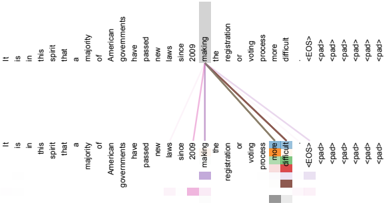

Document ID: 47
Source: 1706.03762.pdf
Content:
The image is a graphical representation of a decision tree, a common tool in decision analysis and machine learning. The text in the image is not directly readable, but it is likely to be the labels or instructions for the decision-making process. The structure of the tree, with its branching paths and decision points, indicates a process of making choices based on certain conditions. Each decision point leads to a different outcome or a new decision point, forming a complex network that can be used to model and solve decision problems. The specifics of the text and the decision-making process would require further context or a clearer image to provide a detailed explanation.
Image:


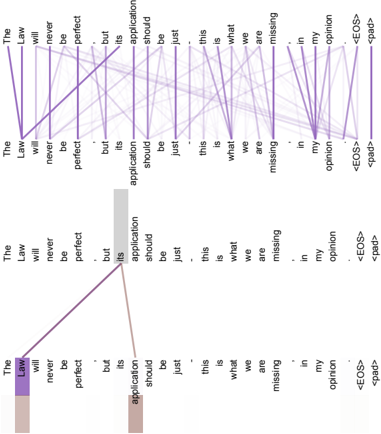

Document ID: 48
Source: 1706.03762.pdf
Content:
The text in the image is a mix of English and what appears to be a foreign language, possibly Latin or another Romance language. It is not fully legible due to the image resolution, but it seems to be discussing legal concepts such as "The Law," "will," "never," "be," "perfect," "but," "its," "application," "should," "be," "just," "this," "is," "what," "we," "are," "missing," "in," "my," "option," and "EOS" (End of Sentence). The text is fragmented and does not form complete sentences, making it difficult to provide a full interpretation.
Image:


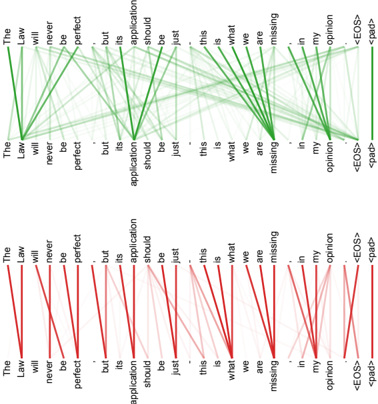

In [10]:
import itertools
from docling_core.types.doc.document import RefItem
from IPython.display import display

# Print all created documents
for document in itertools.chain(texts, tables):
    print(f"Document ID: {document.metadata['doc_id']}")
    print(f"Source: {document.metadata['source']}")
    print(f"Content:\n{document.page_content}")
    print("=" * 80)  # Separator for clarity

for document in pictures:
    print(f"Document ID: {document.metadata['doc_id']}")
    source = document.metadata['source']
    print(f"Source: {source}")
    print(f"Content:\n{document.page_content}")
    docling_document = conversions[source]
    ref = document.metadata['ref']
    picture = RefItem(cref=ref).resolve(docling_document)
    image = picture.get_image(docling_document)
    print("Image:")
    display(image)
    print("=" * 80)  # Separator for clarity


## Populate the vector database

Using the embedding model, we load the documents from the text chunks and generated image captioning into a vector database. Creating this vector database allows us to easily conduct a semantic similarity search across our documents.

NOTE: Population of the vector database can take some time depending on your embedding model and service.

### Choose your vector database

Specify the database to use for storing and retrieving embedding vectors.

To connect to a vector database other than ChromaDB, replace this code cell with one from [this Vector Store recipe](https://github.com/ibm-granite-community/granite-kitchen/blob/main/recipes/Components/Langchain_Vector_Stores.ipynb).

In [ ]:
__import__('pysqlite3')
import sys
sys.modules['sqlite3'] = sys.modules.pop('pysqlite3')

from langchain_core.vectorstores import VectorStore
from langchain_chroma import Chroma

vector_db: VectorStore = Chroma(embedding_function=embeddings_model)

We now add all the LangChain documents for the text, tables and image descriptions to the vector database.

In [12]:
import itertools

documents = list(itertools.chain(texts, tables, pictures))
ids = vector_db.add_documents(documents)
print(f"{len(ids)} documents added to the vector database")

48 documents added to the vector database


## Step 4: RAG with Granite

Now that we have successfully converted our documents and vectorized them, we can set up out RAG pipeline.

### Retrieve relevant chunks



Here we test the vector database by searching for chunks with relevant information to our query in the vector space. We display the documents associated with the retrieved image description.

Feel free to try different queries.

In [ ]:
query = "How does the multihead attention work?" # EXAMPLE 1
# query = "How much was spent on food distribution relative to the amount of food distributed?" # EXAMPLE 2

for doc in vector_db.as_retriever().invoke(query):
    print(doc)
    print("=" * 80)  # Separator for clarity

page_content='Figure 2: (left) Scaled Dot-Product Attention. (right) Multi-Head Attention consists of several attention layers running in parallel.
of the values, where the weight assigned to each value is computed by a compatibility function of the query with the corresponding key.' metadata={'source': '1706.03762.pdf', 'ref': '#/texts/36 #/texts/38', 'doc_id': 9}
page_content='The Transformer uses multi-head attention in three different ways:
- In "encoder-decoder attention" layers, the queries come from the previous decoder layer, and the memory keys and values come from the output of the encoder. This allows every position in the decoder to attend over all positions in the input sequence. This mimics the typical encoder-decoder attention mechanisms in sequence-to-sequence models such as [38, 2, 9].
- The encoder contains self-attention layers. In a self-attention layer all of the keys, values and queries come from the same place, in this case, the output of the previous layer in th

The returned document should be responsive to the query. Let's go ahead and construct our RAG pipeline.

### Create the RAG pipeline for Granite

First we create the prompts for Granite to perform the RAG query. We use the Granite chat template and supply the placeholder values that the LangChain RAG pipeline will replace.

Next, we construct the RAG pipeline by using the Granite prompt templates previously created.


In [14]:
from ibm_granite_community.langchain.chains.combine_documents import create_stuff_documents_chain
from langchain_classic.chains.retrieval import create_retrieval_chain
from langchain_core.prompts import ChatPromptTemplate

# Create a Granite prompt for question-answering with the retrieved context
prompt_template = ChatPromptTemplate.from_template("{input}")

# Assemble the retrieval-augmented generation chain
combine_docs_chain = create_stuff_documents_chain(
    llm=model,
    prompt=prompt_template,
)
rag_chain = create_retrieval_chain(
    retriever=vector_db.as_retriever(),
    combine_docs_chain=combine_docs_chain,
)

### Generate a retrieval-augmented response to a question

The pipeline uses the query to locate documents from the vector database and use them as context for the query.

In [15]:
from ibm_granite_community.notebook_utils import wrap_text

output = rag_chain.invoke({"input": query})

print("---"*10)
print("### Response:")
print(wrap_text(output['answer']))

INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/models/ibm-granite/granite-4.0-h-small "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST https://api.replicate.com/v1/models/ibm-granite/granite-4.0-h-small/predictions "HTTP/1.1 201 Created"
INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/6neg6yjqwnrnc0cxssba0d6re4 "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/6neg6yjqwnrnc0cxssba0d6re4 "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://api.replicate.com/v1/predictions/6neg6yjqwnrnc0cxssba0d6re4 "HTTP/1.1 200 OK"


------------------------------
### Response:
Multi-head attention works by running several attention layers in parallel,
allowing the model to attend to different positions in the input data. This is
particularly useful in tasks involving sequence data like natural language
processing. In the Transformer model, multi-head attention is used in three
different ways: in "encoder-decoder attention" layers, self-attention layers in
the encoder, and self-attention layers in the decoder. Each of these uses the
attention mechanism to allow different positions in the input sequence to attend
to each other, enabling the model to capture dependencies and relationships
within the data.


Awesome! We have created an AI application that can successfully leverage knowledge from the source documents' text and images.

## Next Steps

- Explore advanced RAG workflows for other industries.
- Experiment with other document types and larger datasets.
- Optimize prompt engineering for better Granite responses.

Thank you for using this recipe!